## Green's functions vs. finite elements in 2D

In 1D we built $u = G * f$ on the whole real line. Now we move to 2D, where the generic Green's function is

$$
G(x) = \frac{1}{2\pi}\ln\|x\|, \qquad \Delta G = \delta .
$$

A finite element solver cannot work on all of $\mathbb{R}^2$: it needs a bounded domain and a boundary condition. Here we solve

$$
\Delta u = f \ \text{ in } [-L, L]^2, \qquad u = 0 \ \text{ on the boundary},
$$

In [1]:
import os
# os.environ.setdefault("VISKEX_PYVISTA_BACKEND", "html") 

import numpy as np
import ufl
from mpi4py import MPI
from scipy.special import exp1
import dolfinx
from dolfinx.fem.petsc import LinearProblem
import viskex
from dolfinx import geometry
import matplotlib.pyplot as plt

### Exact solution

As in 1D we use a Gaussian forcing with total mass 1,

$$
f(x) = \frac{1}{2\pi\sigma^2} e^{-\|x\|^2 / 2\sigma^2}.
$$

After converting to polar, a solution to the convolution for this forcing can be found:

$$
u(r) = \frac{1}{4\pi}\left[\ln r^2 + E_1\!\left(\frac{r^2}{2\sigma^2}\right)\right].
$$
for $r != 0$ where $E_1$ is the exponential integral function, and $u(0) = \frac{1}{4\pi}\left(\ln 2\sigma^2 - \gamma\right)$, where $\gamma$ is the Euler–Mascheroni constant.

In [2]:
sigma = 0.2

def u_exact(r):
    r2 = np.asarray(r, dtype=float)**2
    with np.errstate(divide='ignore', invalid='ignore'):
        val = (np.log(r2) + exp1(r2/(2*sigma**2)))/(4*np.pi)
    return np.where(r2 > 0, val, (np.log(2*sigma**2) - np.euler_gamma)/(4*np.pi))

### The mesh

Finite elements chop the domain into small triangles. For simple geometries (squares, disks, rectangles) you can create the mesh inside FEniCSx. For more complicated features, you can import a mesh generated with another program. 

In [3]:
domain = dolfinx.mesh.create_rectangle(MPI.COMM_WORLD, [[-1,-1],[1,1]],[8,8], dolfinx.mesh.CellType.quadrilateral)
viskex.dolfinx.plot_mesh(domain)

Widget(value='<iframe src="http://localhost:61115/index.html?ui=P_0x320d46f90_0&reconnect=auto" class="pyvista…

### Finite Elements and FEniCSx

Finite elements is a strategy for solving boundary and initial value problems by employing a Galerkin technique. Galerkin techniques are much like the distributional methods we have investigated for Green's functions: we test our proposed solution against a set of test functions. 

Unlike distributional methods whose set of test functions have infinite members, we will test against a tightly controlled and finite set of test functions, which are usually piecewise polynomials. For the basic method, we choose our set of test functions equal to the number of interior (non-boundary) nodes. 

multiply $\Delta u = f$ by a test function $v$ *that vanishes on* $\partial \Omega$ and integrate by parts: 

$$
\int_\Omega \nabla u \cdot \nabla v \, dx = -\int_\Omega f\, v\, dx \qquad \text{for every test function } v .
$$

FEniCSx turns this into a linear system $A\mathbf{u} = \mathbf{b}$ and solves it.

In [4]:
def f_ufl(x):
    return ufl.exp(-ufl.dot(x, x)/(2*sigma**2))/(2*np.pi*sigma**2)

FEniCSx has several components. The main one, dolfinx, controls the actual FE system. The other main one you will interact with is UFL, which is actually a real name: it stands for Unified Form Language, and is used to define high level mathematical operations (like take the gradient of a functions and integrate it) and turn this into a structure that the numerical solver can understand. 

In [5]:
def solve_poisson(L:float, f, boundary_func, cells_per_unit=40):
    """Solve Δu = f on the square [-L, L]^2 with u = boundary_value on the edges."""
    # mesh: about 40 triangles per unit length in each direction
    n = int(2*L*cells_per_unit)
    domain = dolfinx.mesh.create_rectangle(MPI.COMM_WORLD, [[-L, -L], [L, L]], [n, n])
    V = dolfinx.fem.functionspace(domain, ("Lagrange", 1))      # piecewise-linear functions


    # boundary condition: u = boundary_value on every edge of the square
    u_bc = dolfinx.fem.Function(V)
    u_bc.interpolate(boundary_func)
    domain.topology.create_connectivity(1, 2)
    boundary_dofs = dolfinx.fem.locate_dofs_topological(V, 1, dolfinx.mesh.exterior_facet_indices(domain.topology))
    bc = dolfinx.fem.dirichletbc(u_bc, boundary_dofs)

    # weak form:  ∫ ∇u·∇v dx = -∫ f v dx
    u, v = ufl.TrialFunction(V), ufl.TestFunction(V)
    x = ufl.SpatialCoordinate(domain)
    a = ufl.inner(ufl.grad(u), ufl.grad(v))*ufl.dx
    rhs = -f(x)*v*ufl.dx

    problem = LinearProblem(a, rhs, bcs=[bc], petsc_options_prefix="poisson_",
                            petsc_options={"ksp_type": "preonly", "pc_type": "lu"})
    return problem.solve()

## Example 1: the box $[-1, 1]^2$

In [6]:
zero_func = lambda x: np.zeros_like(x[0])
u1 = solve_poisson(1.0, f_ufl, zero_func)

In [7]:
def compare_along_x(uh, u_exact, title):
    # create a line along y = 0
    L = np.abs(uh.function_space.mesh.geometry.x[:, 0]).max()
    xs = np.linspace(-0.999*L, 0.999*L, 401)
    P = np.zeros((len(xs), 3))
    P[:, 0] = xs

    # Query the mesh for evaluation points
    msh = uh.function_space.mesh
    tree = geometry.bb_tree(msh, msh.topology.dim)
    candidates = geometry.compute_collisions_points(tree, P)
    colliding = geometry.compute_colliding_cells(msh, candidates, P)
    cells = np.array([colliding.links(i)[0] for i in range(len(P))], dtype=np.int32)
    eval = uh.eval(P, cells).ravel()

    #Plot
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(xs, eval, lw=2,label='finite elements')
    ax.plot(xs, u_exact(np.abs(xs)), '--', lw=2, label='Greens G * f')
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xlabel('x  (along y = 0)'); ax.set_ylabel('u'); ax.set_title(title); ax.legend()
    fig.tight_layout()
    plt.show()

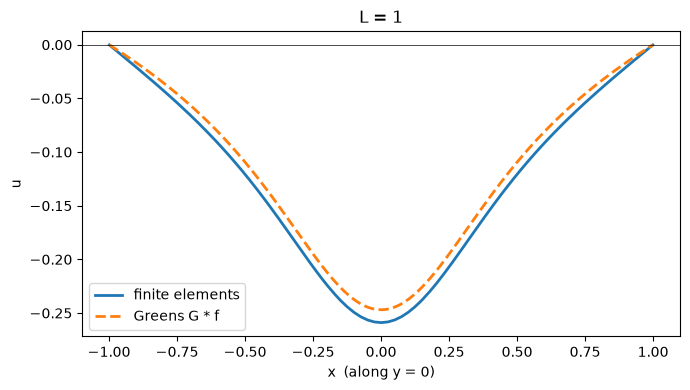

In [8]:
compare_along_x(u1, u_exact, "L = 1")

In [9]:
viskex.dolfinx.plot_scalar_field(u1, "u", warp_factor=3.0, show_edges=False)

Widget(value='<iframe src="http://localhost:61115/index.html?ui=P_0x32b33f740_1&reconnect=auto" class="pyvista…

The finite element solution lands right on top of $G * f$. Does the boundary simply irrelevant?

Remember Green's Functions from 1D: far away from the point source, u has to look like the Green's function. In this case, for sufficiently large $x$, 

$$ 
u \approx \frac{1}{2 \pi} ln ||x ||
$$

If $x = 1$...

## Example 2: the box $[-4, 4]^2$

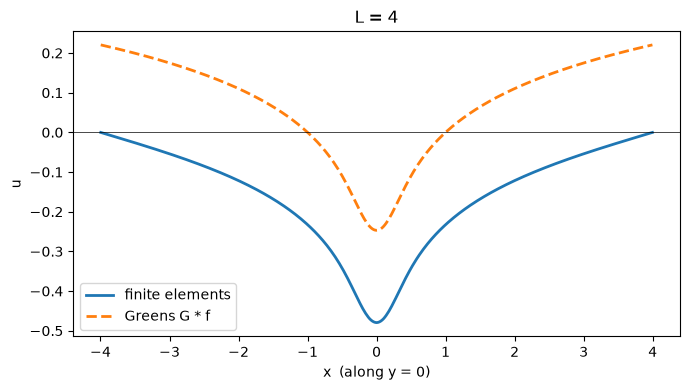

gap at the origin: 0.233     (1/2π) ln 4 = 0.221


In [10]:
u4 = solve_poisson(4.0, f_ufl,zero_func)
compare_along_x(u4, u_exact, "L = 4")

P = np.zeros((1,3))
msh = u4.function_space.mesh
tree = geometry.bb_tree(msh, msh.topology.dim)
candidates = geometry.compute_collisions_points(tree, P)
colliding = geometry.compute_colliding_cells(msh, candidates, P)
cells = np.array([colliding.links(i)[0] for i in range(len(P))], dtype=np.int32)
eval = u4.eval(P, cells).ravel()

offset = u_exact(0.0) - eval[0]
print(f"gap at the origin: {offset:.3f}     (1/2π) ln 4 = {np.log(4)/(2*np.pi):.3f}")

Now the two curves are shifted by about $\frac{1}{2\pi}\ln 4$. Unfortunately, Green's functions are problem and geometry specific, which makes them ill-adapted to changing geometries. 

But a constant shift does not change $\nabla u$. If the quantity we care about is the gradient, the boundary matters much less. That is exactly the situation in potential flow.

## Potential flow

In an ideal fluid with no vorticity, the velocity is the gradient of a potential, $\mathbf{v} = \nabla \phi$. Conservation of mass says

$$
\nabla \cdot \mathbf{v} = \Delta \phi = f ,
$$

where $f > 0$ is a **source** (fluid is injected) and $f < 0$ is a **sink** (fluid is removed). So the same Poisson solver computes flows.

Put a Gaussian source at $(-1, 0)$ and an equal sink at $(1, 0)$. The colour is the speed $|\mathbf{v}|$ and the white lines are streamlines, the paths whose tangents are the fluid velocities. 

In [11]:
from viskex.dolfinx_plotter import DolfinxPlotter
from viskex.dolfinx_converter import DolfinxConverter
import pyvista

In [12]:
def plot_flow(phi, sources, inflow=False):
    W = dolfinx.fem.functionspace(phi.function_space.mesh, ("Lagrange", 1, (2,)))
    v = dolfinx.fem.Function(W)
    v.interpolate(dolfinx.fem.Expression(ufl.grad(phi), W.element.interpolation_points))
    L = np.abs(phi.function_space.mesh.geometry.x[:, 0]).max()

    angles = np.linspace(0, 2*np.pi, 24, endpoint=False)
    seeds = [np.column_stack([sx + 0.3*np.cos(angles), sy + 0.3*np.sin(angles)]) for sx, sy in sources]
    if inflow:
        ys = np.linspace(-0.95*L, 0.95*L, 25)
        seeds.append(np.column_stack([np.full_like(ys, -0.97*L), ys]))
    seeds = np.vstack(seeds)

    # velocity plot
    plotter = DolfinxPlotter.plot_vector_field(v, "velocity", plotter=pyvista.Plotter(window_size=(700, 650)),
                                               show_edges=False, cmap="viridis")
    # streamline plot
    grid = DolfinxConverter.convert_field(v, "velocity")
    lines = grid.streamlines_from_source(pyvista.PolyData(np.column_stack([seeds, np.zeros(len(seeds))])),
                                         vectors="velocity", surface_streamlines=True,
                                         integration_direction="both", max_length=50.0,
                                         initial_step_length=0.1, max_steps=20000)
    plotter.add_mesh(lines, color="white", line_width=1.5)
    plotter.view_xy()
    plotter.show()

In [13]:
d = 1.0
def source_sink(x):
    return f_ufl(x + ufl.as_vector([d, 0])) - f_ufl(x - ufl.as_vector([d, 0]))

phi = solve_poisson(3.0, source_sink, zero_func)
plot_flow(phi, sources=[(-d, 0)])

Widget(value='<iframe src="http://localhost:61115/index.html?ui=P_0x32b45edb0_2&reconnect=auto" class="pyvista…

Fluid leaves the source and arcs over to the sink: the same picture as the field lines of a bar magnet. Because the total forcing is zero (as much fluid enters as leaves), this flow decays far away, so the box boundary disturbs it much less than it disturbed the single source in Example 2.

### Adding a uniform stream

Now set the boundary values to $\phi = Ux$ instead of $0$. Then, $\nabla \phi|_{\partial \Omega} = [U, 0 ,0]^T$

In [14]:
U = 0.2
phi = solve_poisson(3.0, source_sink, lambda x: U*x[0])
plot_flow(phi, sources=[(-d, 0)], inflow=True)

Widget(value='<iframe src="http://localhost:61115/index.html?ui=P_0x32b45f350_3&reconnect=auto" class="pyvista…

This is the **Rankine oval**. It can be used to model flow past an oval object (say a bridge pier). You can learn more about source-sink flows at: (https://web.mit.edu/16.unified/www/FALL/fluids/Lectures/f15.pdf)

Try to implement one of the examples yourself! 

## The true power of finite elements

In [15]:
import urllib.request
import mpi4py

In [16]:
msh_filename = "data/garda.msh"
if not os.path.isfile(msh_filename):
    os.makedirs("data", exist_ok=True)
    msh_url = (
        "https://raw.githubusercontent.com/FEMlium/FEMlium/main/"
        "tutorials/01_introduction/data/garda.msh")
    with urllib.request.urlopen(msh_url) as response, open(msh_filename, "wb") as msh_file:
        msh_file.write(response.read())

In [17]:
mesh, subdomains, boundaries, *_ = dolfinx.io.gmsh.read_from_msh(
    "data/garda.msh", comm=mpi4py.MPI.COMM_WORLD, rank=0, gdim=2)
assert subdomains is not None
assert boundaries is not None

Info    : Reading 'data/garda.msh'...
Info    : 2390 entities
Info    : 3937 nodes
Info    : 7872 elements
Info    : Done reading 'data/garda.msh'


In [18]:
viskex.dolfinx.plot_mesh(mesh)

Widget(value='<iframe src="http://localhost:61115/index.html?ui=P_0x32b325c40_4&reconnect=auto" class="pyvista…

In [19]:
viskex.dolfinx.plot_mesh_tags(mesh, subdomains, "subdomains")

Widget(value='<iframe src="http://localhost:61115/index.html?ui=P_0x32b326690_5&reconnect=auto" class="pyvista…

In [28]:
viskex.dolfinx.plot_mesh_tags(mesh, boundaries, "boundaries")

Widget(value='<iframe src="http://localhost:61115/index.html?ui=P_0x372c3a150_6&reconnect=auto" class="pyvista…

Almost all of the boundary is comprised of shoreline, but there are 3 different tags corresponding to shore and inlet/outlet rivers. Exercise: find the inlet/outlet rivers. 

In [29]:
boundaries.values

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

### A pollution source in the lake

A pollutant spreading by diffusion from a steady source satisfies $-\Delta c = f$ (note the sign: with $f \ge 0$ this keeps the concentration $c \ge 0$). We dump a narrow Gaussian of total mass 1 near the middle of the lake.

The mesh is coarse in open water (triangles 1–2 km across), much wider than the Gaussian, so we refine it locally around the source first. Refining makes a new mesh, so the facet tags have to be transferred to it.

In [31]:
x0 = np.array([631544.0, 5054516.0])   # source location
sigma_lake = 250.0                      # width of the source (metres)

def pollution(x):
    r2 = (x[0] - x0[0])**2 + (x[1] - x0[1])**2
    return ufl.exp(-r2/(2*sigma_lake**2))/(2*np.pi*sigma_lake**2)

# make sure the source is actually in the lake
tree = geometry.bb_tree(mesh, mesh.topology.dim)
P = np.array([[x0[0], x0[1], 0.0]])
assert len(geometry.compute_colliding_cells(mesh, geometry.compute_collisions_points(tree, P), P).links(0)) > 0

# refine near the source a few times, carrying the facet tags along to the new mesh
for _ in range(4):
    edges = dolfinx.mesh.locate_entities(mesh, 1, lambda x: np.hypot(x[0] - x0[0], x[1] - x0[1]) < 8*sigma_lake)
    new_mesh, parent_cell, parent_facet = dolfinx.mesh.refine(
        mesh, edges, option=dolfinx.mesh.RefinementOption.parent_cell_and_facet)
    new_mesh.topology.create_entities(1)
    boundaries = dolfinx.mesh.transfer_meshtag(boundaries, new_mesh, parent_cell, parent_facet)
    mesh = new_mesh

viskex.dolfinx.plot_mesh(mesh)

Widget(value='<iframe src="http://localhost:61115/index.html?ui=P_0x32b359a90_7&reconnect=auto" class="pyvista…

In [36]:
V = dolfinx.fem.functionspace(mesh, ("Lagrange", 1))      # piecewise-linear functions

# boundary conditions: Dirichlet 0 on the shoreline 
# nothing is imposed on the inlet/outlet: we assume the flow effect is negligible. 
mesh.topology.create_connectivity(1, 2)
bcs = [dolfinx.fem.dirichletbc(0.0, dolfinx.fem.locate_dofs_topological(V, 1, boundaries.find(1)), V)]

# weak form:  ∫ ∇c·∇v dx = ∫ f v dx
c, v = ufl.TrialFunction(V), ufl.TestFunction(V)
x = ufl.SpatialCoordinate(mesh)
a = ufl.inner(ufl.grad(c), ufl.grad(v))*ufl.dx
rhs = pollution(x)*v*ufl.dx

problem = LinearProblem(a, rhs, bcs=bcs, petsc_options_prefix="lake_",
                        petsc_options={"ksp_type": "preonly", "pc_type": "lu"})
ch = problem.solve()

print(f" max concentration: {ch.x.array.max():.4f}")

 max concentration: 0.3158


In [37]:
viskex.dolfinx.plot_scalar_field(ch, "concentration", show_edges=False)

Widget(value='<iframe src="http://localhost:61115/index.html?ui=P_0x32b247e60_10&reconnect=auto" class="pyvist…

To go beyond this, we could choose to model more effects: impose some flow boundary conditions on the rivers feeding Lake Garda, consider a time-dependent diffusion equation to track how the pollution spreads over time, add some wind speed advection term, model the fluid flow on the surface, use radar data to create a 3D model and see how pollution settles into substrate. 

The choices are endless. The task a modeler is determining which are important to make the expense of adding them worth it for the final decision. 